# 12. Shot map grid

The card's shot map shows where a player shoots from in the offensive zone. Raw shots never go public, so this notebook pre-counts them into 5 ft x 5 ft cells and saves only the counts:

- `app_data/shot_grid.csv`: one row per non-empty cell per player-season (`playerId, season, gx, gy, shots, goals`), offensive zone only
- `app_data/shot_totals.csv`: one row per player-season (`playerId, season, unblocked_shots, unblocked_goals, oz_shots`), every zone

They are two files because they have different shapes: cells only cover the offensive zone, while the totals count every unblocked shot.

Every shot is folded onto one end exactly as in notebook 11, so the net is at x = 89 and y > 0 is the shooter's left, seen from the point looking at the net. Step 3 checks that before anything is saved.

## 1. Setup and fold

In [1]:
import sys
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

sys.path.append("../src")
from player_card import draw_card, shot_cell, season_label, SHOT_X, SHOT_Y, SHOT_CELL

DATA = Path("../data")
APP_DATA = Path("../app_data")
GRID_PATH = APP_DATA / "shot_grid.csv"
TOTALS_PATH = APP_DATA / "shot_totals.csv"
KEY = ["playerId", "season"]

shots = pd.read_parquet(DATA / "shots_2021-2025.parquet")
no_id = shots["shooterPlayerId"].isna() | shots["shooterPlayerId"].eq(0)
print(f"Unblocked shots: {len(shots):,}. Dropped {int(no_id.sum())} with no shooter ID ({int(shots.loc[no_id, 'goal'].sum())} goals).")
shots = shots[~no_id].copy()
shots["playerId"] = shots["shooterPlayerId"].astype("int64")
shots["season"] = shots["season"].astype("int64")


def fold(x, y):
    """Same as notebook 11: put every shot on the right end of the rink, x = |x|, and y flips with it."""
    side = np.sign(x).replace(0, 1)
    return x.abs(), y * side


shots["fx"], shots["fy"] = fold(shots["arenaAdjustedXCord"], shots["arenaAdjustedYCord"])

Unblocked shots: 566,158. Dropped 24 with no shooter ID (1 goals).


## 2. Build the grid and totals (in memory)

Offensive zone = blue line to end boards (25 <= x <= 100). Shots just past the side boards (the arena adjustment can push a few there) are clipped into the edge cells, so every offensive-zone shot is on the map.

In [2]:
oz = shots[(shots["fx"] >= SHOT_X[0]) & (shots["fx"] <= SHOT_X[1])].copy()
oz["gx"], oz["gy"] = shot_cell(oz["fx"], oz["fy"])
print(f"Offensive-zone shots: {len(oz):,} of {len(shots):,} ({len(oz) / len(shots):.1%}); "
      f"clipped in from past the side boards: {int((oz['fy'].abs() > SHOT_Y[1]).sum()):,}")

grid = oz.groupby(KEY + ["gx", "gy"]).agg(shots=("goal", "size"), goals=("goal", "sum")).reset_index()
totals = shots.groupby(KEY).agg(unblocked_shots=("goal", "size"), unblocked_goals=("goal", "sum")).reset_index()
totals = totals.merge(oz.groupby(KEY).size().rename("oz_shots").reset_index(), on=KEY, how="left")
totals["oz_shots"] = totals["oz_shots"].fillna(0).astype(int)
print(f"Grid: {len(grid):,} non-empty cells for {grid[KEY].drop_duplicates().shape[0]:,} player-seasons")
print(f"Totals: {len(totals):,} player-seasons")

Offensive-zone shots: 549,807 of 566,134 (97.1%); clipped in from past the side boards: 1,243
Grid: 289,937 non-empty cells for 4,686 player-seasons
Totals: 4,690 player-seasons


## 3. Orientation check (before saving)

Seen from the point looking at the net, Alex Ovechkin's favorite spot is the **left** faceoff circle, so in 2021-22 his top cells must be on the left (y > 0). If they aren't, the map is mirrored and the notebook stops here without saving.

Steven Stamkos (his power-play one-timer spot) should lean left too. That one is reported, not asserted.

In [3]:
cards = pd.read_csv(APP_DATA / "cards.csv").merge(totals, on=KEY, how="left")
cards[["unblocked_shots", "unblocked_goals", "oz_shots"]] = cards[["unblocked_shots", "unblocked_goals", "oz_shots"]].fillna(0)
grid_by = grid.set_index(KEY).sort_index()


def rows_for(pid, season):
    """This player-season's grid rows (always a table, possibly empty)."""
    if (pid, season) in grid_by.index:
        return grid_by.loc[[(pid, season)]].reset_index(drop=True)
    return grid.iloc[:0][["gx", "gy", "shots", "goals"]]


def top_cells(name, season=2021, n=5):
    pid = cards.loc[(cards["name"] == name) & (cards["season"] == season), "playerId"].iloc[0]
    top = rows_for(pid, season).nlargest(n, "shots")
    top = top.assign(x=SHOT_X[0] + SHOT_CELL * (top["gx"] + 0.5), y=SHOT_Y[0] + SHOT_CELL * (top["gy"] + 0.5))
    top["side"] = np.where(top["y"] > 0, "left", np.where(top["y"] < 0, "right", "center"))
    mean_y = np.average(top["y"], weights=top["shots"])
    p = oz[(oz["playerId"] == pid) & (oz["season"] == season)]
    print(f"{name} {season_label(season)}: {len(p)} offensive-zone shots, {(p['fy'] > 0).mean():.0%} on the left (y > 0)")
    print(top[["x", "y", "side", "shots"]].to_string(index=False))
    print(f"Top-{n} cells, weighted mean y = {mean_y:+.1f}: {'LEFT' if mean_y > 0 else 'RIGHT'} side, seen from the point\n")
    return pid, mean_y


ovi_id, ovi_y = top_cells("Alex Ovechkin")
assert ovi_y > 0, "Map looks mirrored: Ovechkin's top cells are on the right. Nothing was saved."
stamkos_id, stamkos_y = top_cells("Steven Stamkos")
print("Stamkos (report only):", "LEFT, as expected" if stamkos_y > 0 else "RIGHT: check the orientation")

Alex Ovechkin 2021-22: 454 offensive-zone shots, 69% on the left (y > 0)
   x    y side  shots
52.5 25.0 left     22
57.5 25.0 left     16
57.5 30.0 left     16
47.5 25.0 left     14
62.5 25.0 left     14
Top-5 cells, weighted mean y = +26.0: LEFT side, seen from the point

Steven Stamkos 2021-22: 322 offensive-zone shots, 70% on the left (y > 0)
   x    y side  shots
67.5 25.0 left     16
72.5 20.0 left     14
67.5 20.0 left     13
77.5 20.0 left      9
57.5 25.0 left      8
Top-5 cells, weighted mean y = +22.0: LEFT side, seen from the point

Stamkos (report only): LEFT, as expected


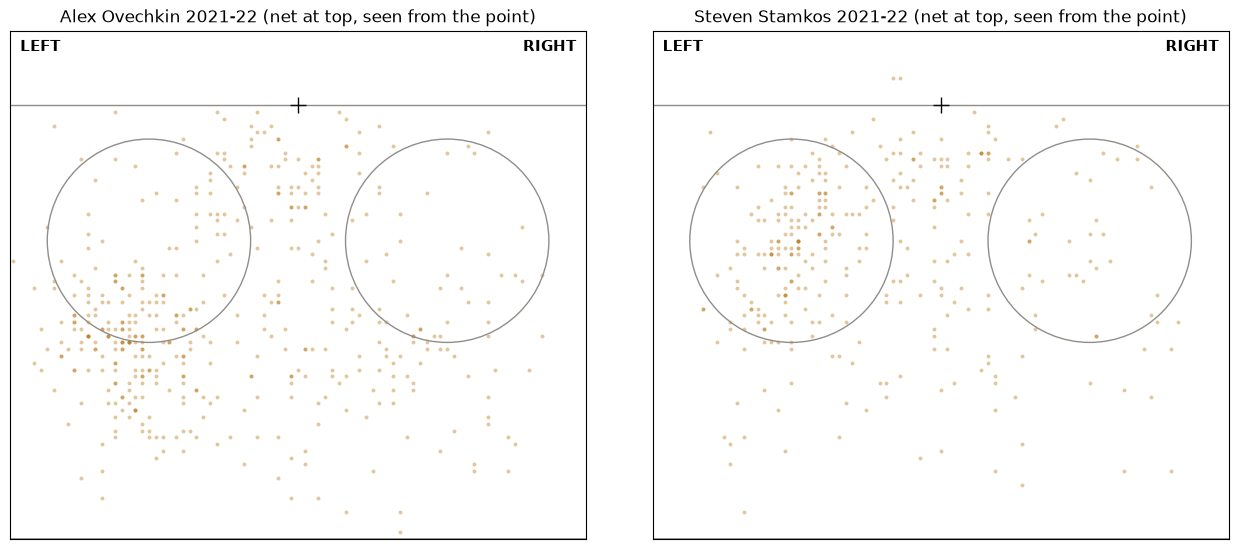

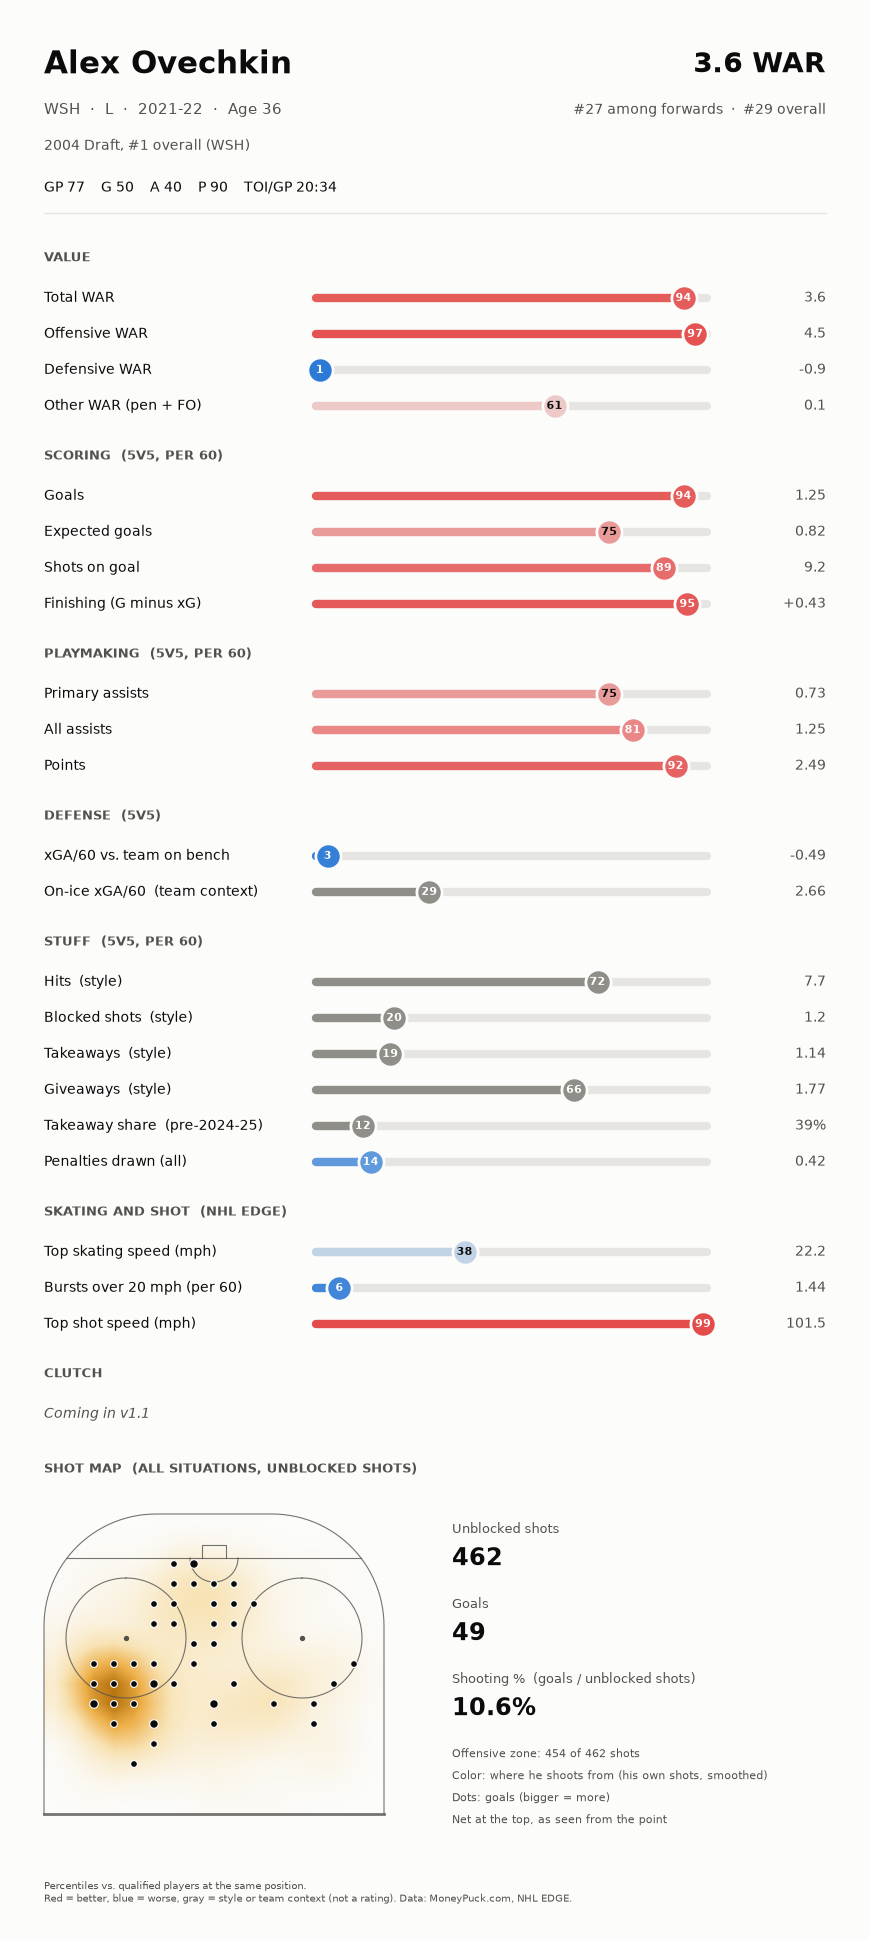

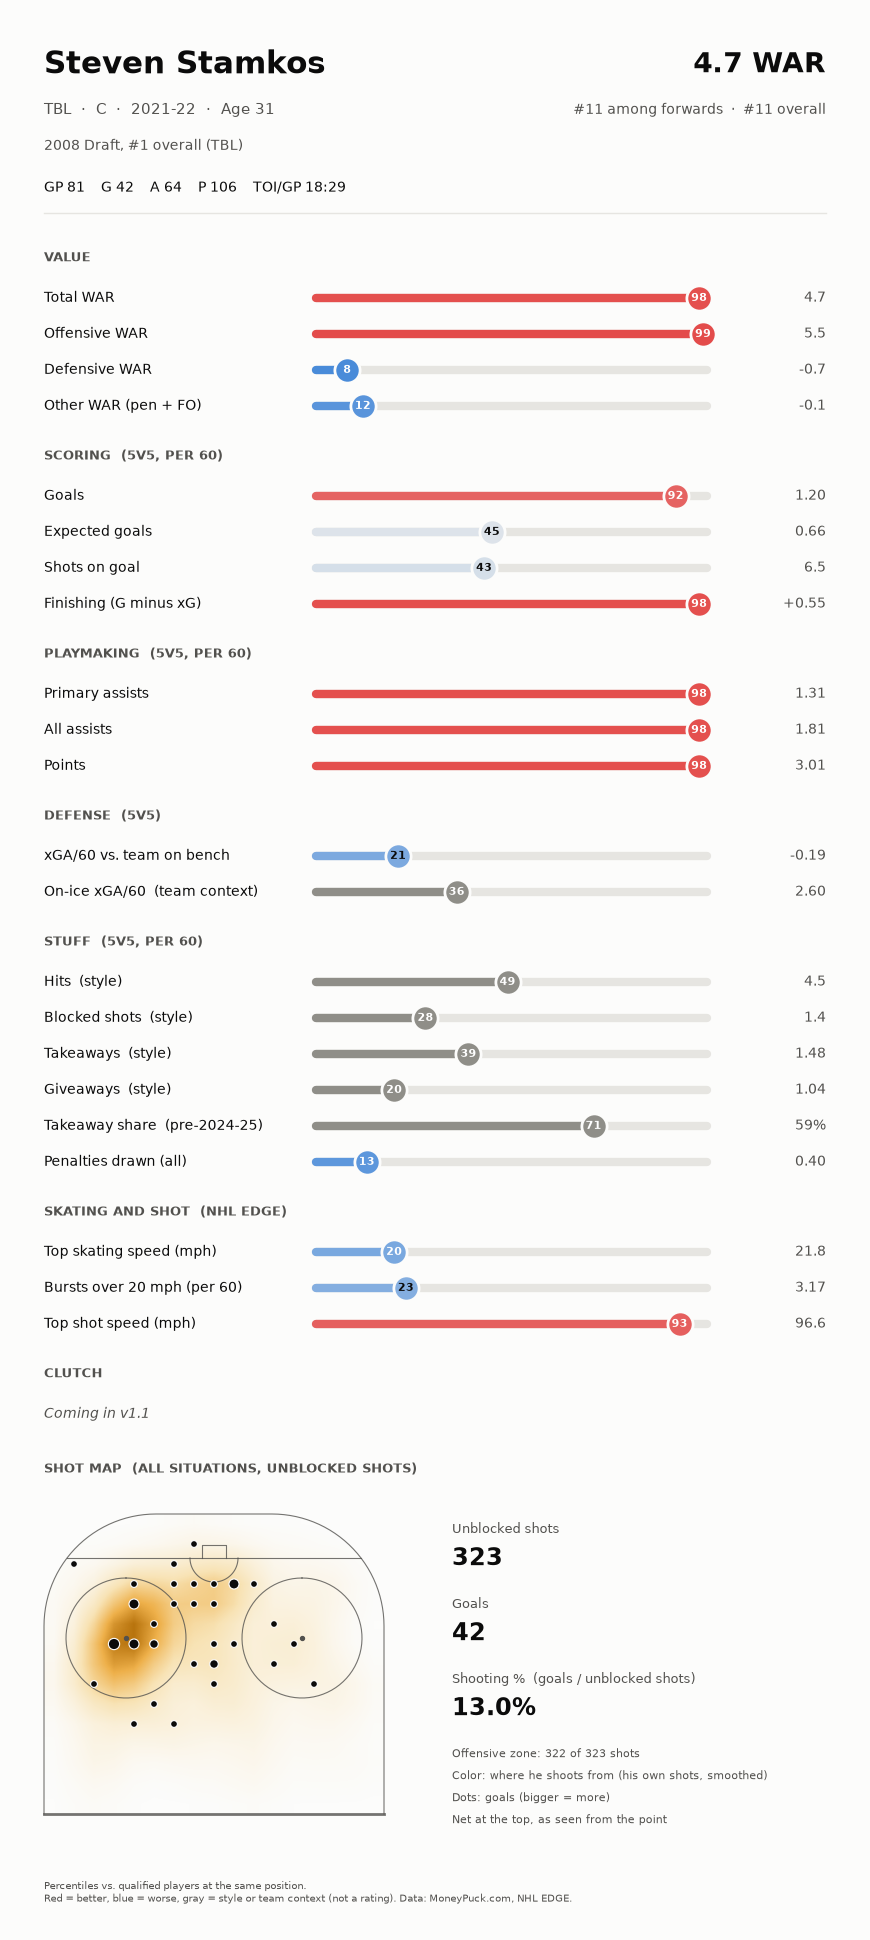

In [4]:
# Two views of the same shots: a plain scatter (net at top, seen from the point) and the card's shot map
checks = [("Alex Ovechkin", ovi_id), ("Steven Stamkos", stamkos_id)]
fig, axes = plt.subplots(1, 2, figsize=(13, 5.5))
for ax, (name, pid) in zip(axes, checks):
    p = oz[(oz["playerId"] == pid) & (oz["season"] == 2021)]
    ax.scatter(-p["fy"], p["fx"], s=8, alpha=0.4, color="#b8740e", linewidths=0)   # screen left = shooter's left (y > 0)
    ax.axhline(89, color="#8f8e88", linewidth=1)
    ax.axhline(25, color="#8f8e88", linewidth=2)
    ax.plot([0], [89], marker="+", color="#0b0b0b", markersize=12)
    for cy in (22, -22):
        ax.add_patch(plt.Circle((-cy, 69), 15, fill=False, color="#8f8e88"))
    ax.text(-41, 97, "LEFT", fontsize=11, fontweight="bold")
    ax.text(41, 97, "RIGHT", fontsize=11, fontweight="bold", ha="right")
    ax.set(xlim=(-42.5, 42.5), ylim=(25, 100), xticks=[], yticks=[],
           title=f"{name} 2021-22 (net at top, seen from the point)")
    ax.set_aspect("equal")
plt.tight_layout()
plt.show()

for name, pid in checks:
    row = cards[(cards["playerId"] == pid) & (cards["season"] == 2021)].iloc[0]
    draw_card(row, row["season_label"], shot_grid=rows_for(pid, 2021))
    plt.show()

## 4. Save

In [5]:
grid.to_csv(GRID_PATH, index=False)
totals.to_csv(TOTALS_PATH, index=False)
for path, table in [(GRID_PATH, grid), (TOTALS_PATH, totals)]:
    print(f"Saved app_data/{path.name}: {path.stat().st_size / 1e6:.1f} MB, {len(table):,} rows")

Saved app_data/shot_grid.csv: 6.3 MB, 289,937 rows
Saved app_data/shot_totals.csv: 0.1 MB, 4,690 rows


## 5. Checks (on the saved files)

- the totals match a fresh recount from the shot data, for every player-season
- each player-season's cells add up to his offensive-zone shots, and never to more goals than his total
- every player-season in the totals exists in `app_data/cards.csv` (reported, not asserted)

In [6]:
grid_back = pd.read_csv(GRID_PATH)
totals_back = pd.read_csv(TOTALS_PATH)

recount = shots.groupby(KEY).agg(shots=("goal", "size"), goals=("goal", "sum")).reset_index()
both = totals_back.merge(recount, on=KEY, how="outer")
same = both["unblocked_shots"].eq(both["shots"]) & both["unblocked_goals"].eq(both["goals"])
print(f"Totals match the shot data for {int(same.sum()):,} of {len(both):,} player-seasons")
print(f"Overall: {totals_back['unblocked_shots'].sum():,} shots and {totals_back['unblocked_goals'].sum():,} goals in the file, "
      f"{len(shots):,} and {int(shots['goal'].sum()):,} in the shot data")
assert same.all(), "Totals do not match the shot data"

cells = grid_back.groupby(KEY).agg(grid_shots=("shots", "sum"), grid_goals=("goals", "sum")).reset_index()
cells = totals_back.merge(cells, on=KEY, how="left").fillna({"grid_shots": 0, "grid_goals": 0})
assert cells["grid_shots"].eq(cells["oz_shots"]).all(), "Grid cells don't add up to offensive-zone shots"
assert cells["grid_goals"].le(cells["unblocked_goals"]).all(), "Grid has more goals than the totals"
print("Grid cells add up to each player-season's offensive-zone shots, and never exceed his goals")

on_card = totals_back.merge(cards[KEY], on=KEY, how="left", indicator=True)
missing = on_card[on_card["_merge"] == "left_only"]
who = shots.drop_duplicates("playerId").set_index("playerId")[["shooterName", "playerPositionThatDidEvent"]].astype(str)
print(f"\nPlayer-seasons with shots but no card in app_data/cards.csv: {len(missing)}")
if len(missing):
    show = missing.join(who, on="playerId").assign(season=lambda d: d["season"].map(season_label))
    print(show[["shooterName", "playerPositionThatDidEvent", "season", "unblocked_shots", "unblocked_goals"]]
          .sort_values("unblocked_shots", ascending=False).to_string(index=False))
print(f"Cards with no unblocked shots (their map is empty): {int((cards['unblocked_shots'] == 0).sum())}")

Totals match the shot data for 4,690 of 4,690 player-seasons
Overall: 566,134 shots and 40,411 goals in the file, 566,134 and 40,411 in the shot data
Grid cells add up to each player-season's offensive-zone shots, and never exceed his goals

Player-seasons with shots but no card in app_data/cards.csv: 47
        shooterName playerPositionThatDidEvent  season  unblocked_shots  unblocked_goals
         Joel Hofer                          G 2025-26                6                0
       Joey Daccord                          G 2025-26                6                0
       Chase De Leo                          C 2021-22                4                0
      Tristan Jarry                          G 2023-24                3                1
   Sergei Bobrovsky                          G 2024-25                3                0
         Mike Smith                          G 2021-22                2                0
   Filip Gustavsson                          G 2024-25                2

## 6. README card

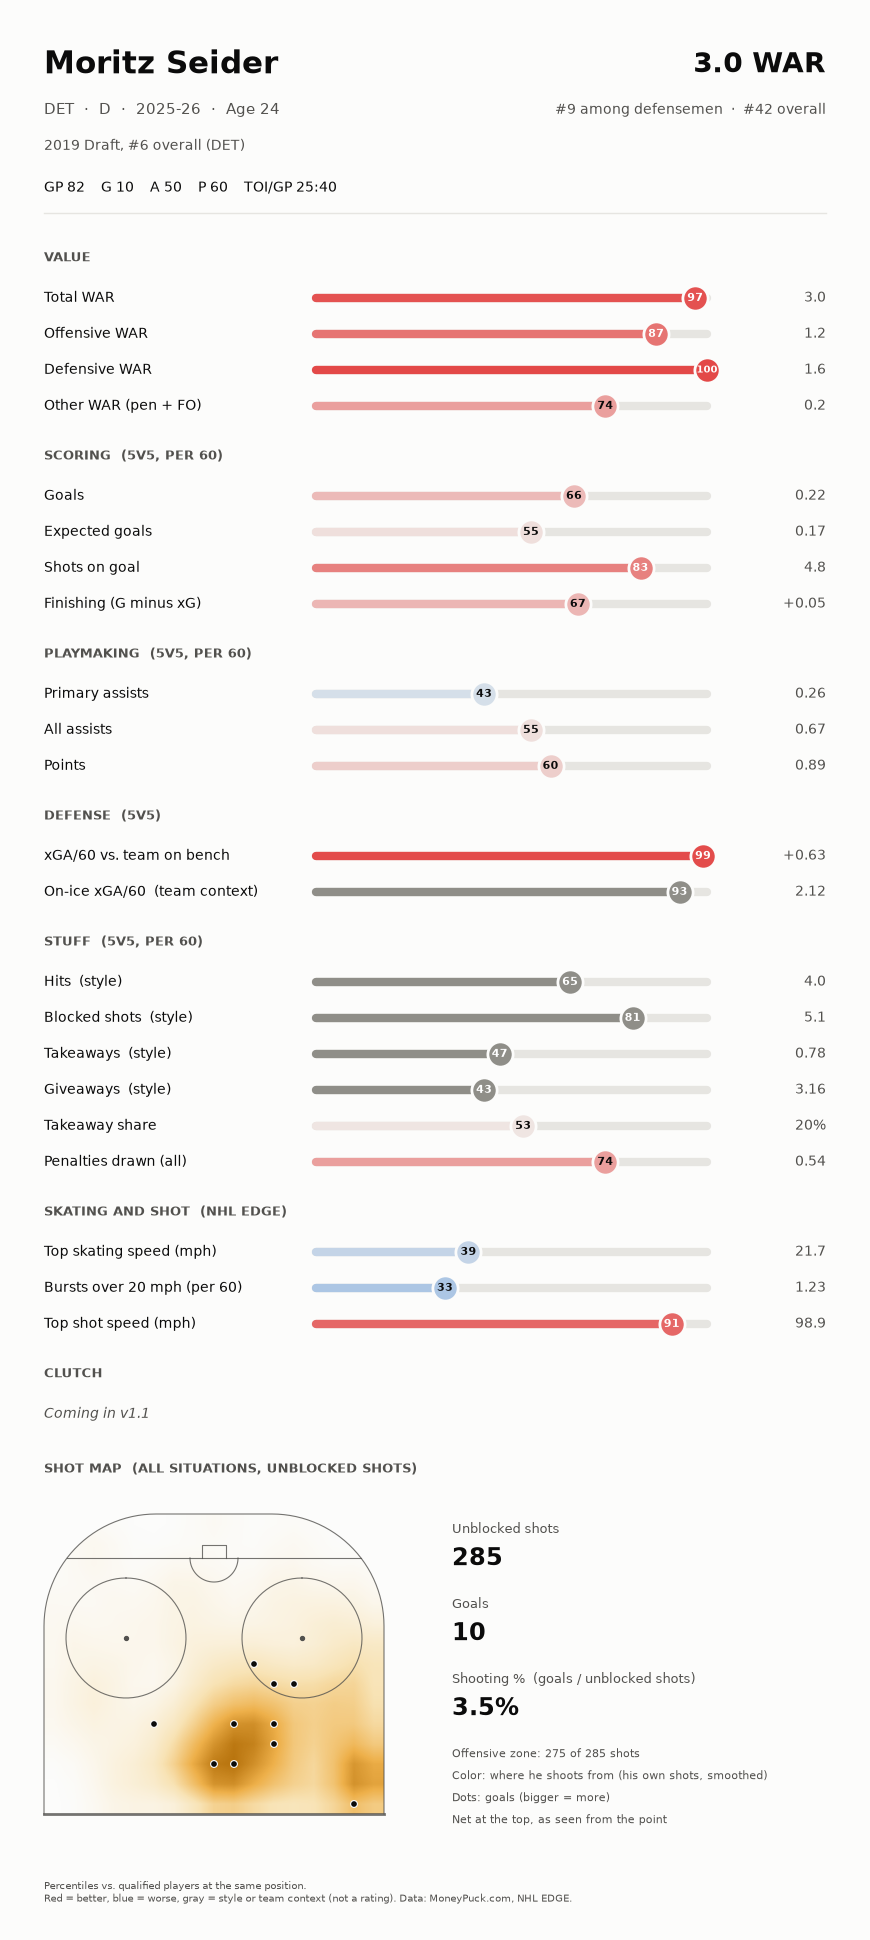

In [7]:
seider = cards[(cards["name"] == "Moritz Seider") & (cards["season"] == 2025)].iloc[0]
draw_card(seider, seider["season_label"], shot_grid=rows_for(seider["playerId"], 2025),
          path=Path("../images/cards/seider_2025-26.png"));